# Generate Filament Gas Dispersion

Set the parameters in the next cell and run all cells to generate data for a gas dispersion scenario. Each run writes 

- `gas.csv` containing the gas concentration for each 2D point in the domain in the `Points:0`, `Points:1`, `C` format,
- `metadata.json` to save the configuration of the scenario (e.g., source parameters, used wind file file, measurement parameters etc.), and
-  `preview.png` which visualizes the generated scenario

into one directory.

Change the occupancy map of the domain, the wind field or source parameters to generate different dispersion scenarios.

In [39]:
# Input data and scenario output directory (paths relative to /app)
OCCUPANCY_PATH = "data/example_multiple_obstacles/occupancy.yaml"
WIND_PATH = "data/example_multiple_obstacles/wind_gt.csv"
SCENARIO_DIR = None  # None creates a name from the source position and seed

# Source and filament model
SOURCE_XY = (4.0, 3.0)
SOURCE_RATE = 1.0
SOURCE_SIGMA = 0.1
FILAMENTS_PER_SEC = 30.0
DIFFUSION_SPEED_STD = 0.9
INITIAL_SIGMA = 0.05
DIFFUSIVITY = 0.005
MAX_AGE = 100.0

# Simulation and time average
DT = 0.05
WARMUP_SECONDS = 30.0
AVERAGING_SECONDS = 10.0
SAMPLE_EVERY_SECONDS = 1.0
SEED = 7

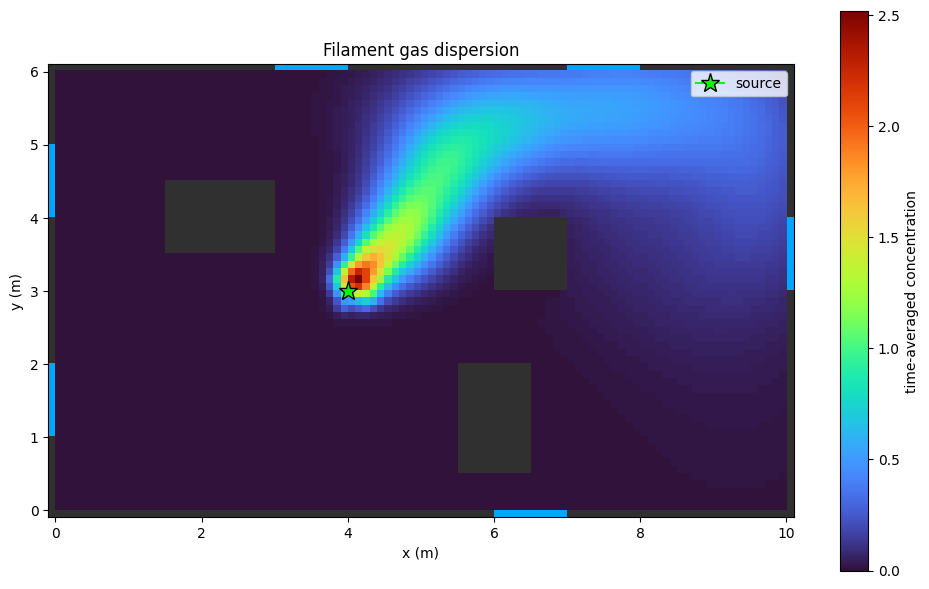

Scenario written to /app/data/example_multiple_obstacles/scenario_source_4_3_seed_7


In [40]:
from pathlib import Path
import json
import os
import sys

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd

project_root = next(
    (directory for directory in (Path.cwd(), *Path.cwd().parents)
     if (directory / "source_estimation_pinn").is_dir()),
    None,
)
if project_root is None:
    raise RuntimeError("Run this notebook from the project directory or a subdirectory.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from dispersion_physics.gas import GasDispersion, GasSource
from source_estimation_pinn.environment import OccupancyGrid, WindField


def project_path(path: str) -> Path:
    path = Path(path)
    return path if path.is_absolute() else project_root / path


occupancy_path = project_path(OCCUPANCY_PATH)
wind_path = project_path(WIND_PATH)
scenario_dir = (
    project_path(SCENARIO_DIR)
    if SCENARIO_DIR is not None
    else occupancy_path.parent / f"scenario_source_{SOURCE_XY[0]:g}_{SOURCE_XY[1]:g}_seed_{SEED}"
)
scenario_dir.mkdir(parents=True, exist_ok=True)
output_csv = scenario_dir / "gas.csv"
metadata_path = scenario_dir / "metadata.json"
image_path = scenario_dir / "preview.png"

occupancy = OccupancyGrid.from_occupancy_file(occupancy_path)
wind = WindField.from_csv(wind_path)
np.random.seed(SEED)
gas = GasDispersion(
    wind_field=wind,
    occupancy=occupancy,
    source=GasSource(position=np.asarray(SOURCE_XY), rate=SOURCE_RATE, sigma=SOURCE_SIGMA),
    filaments_per_sec=FILAMENTS_PER_SEC,
    diffusion_speed_std=DIFFUSION_SPEED_STD,
    initial_sigma=INITIAL_SIGMA,
    diffusivity=DIFFUSIVITY,
    max_age=MAX_AGE,
)

warmup_steps = round(WARMUP_SECONDS / DT)
averaging_steps = round(AVERAGING_SECONDS / DT)
sample_interval = round(SAMPLE_EVERY_SECONDS / DT)
if sample_interval < 1 or averaging_steps % sample_interval:
    raise ValueError("AVERAGING_SECONDS must be divisible by SAMPLE_EVERY_SECONDS")

for _ in range(warmup_steps):
    gas.step(DT)

points = occupancy.free_points
concentration_sum = np.zeros(len(points))
for step in range(1, averaging_steps + 1):
    gas.step(DT)
    if step % sample_interval == 0:
        for start in range(0, len(points), 512):
            concentration_sum[start:start + 512] += gas.concentration_at(points[start:start + 512])

concentrations = concentration_sum / (averaging_steps // sample_interval)
pd.DataFrame({"Points:0": points[:, 0], "Points:1": points[:, 1], "C": concentrations}).to_csv(
    output_csv, index=False, float_format="%.10e"
)

metadata = {
    "model": "Gaussian filament time average",
    "occupancy": os.path.relpath(occupancy_path, scenario_dir),
    "wind": os.path.relpath(wind_path, scenario_dir),
    "files": {"gas": output_csv.name, "preview": image_path.name},
    "source": {"position": list(SOURCE_XY), "rate": SOURCE_RATE, "sigma": SOURCE_SIGMA},
    "filaments_per_sec": FILAMENTS_PER_SEC,
    "diffusion_speed_std": DIFFUSION_SPEED_STD,
    "initial_sigma": INITIAL_SIGMA,
    "diffusivity": DIFFUSIVITY,
    "max_age": MAX_AGE,
    "dt": DT,
    "warmup_seconds": WARMUP_SECONDS,
    "averaging_seconds": AVERAGING_SECONDS,
    "sample_every_seconds": SAMPLE_EVERY_SECONDS,
    "seed": SEED,
    "n_points": len(points),
}
metadata_path.write_text(json.dumps(metadata, indent=2) + "\n")

field = np.ma.masked_all(occupancy.occupancy.shape, dtype=float)
field[occupancy.free_mask] = concentrations
extent = [
    occupancy.lower_bound[0],
    occupancy.upper_bound[0],
    occupancy.lower_bound[1],
    occupancy.upper_bound[1],
]
fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(
    occupancy.occupancy,
    origin="lower",
    extent=extent,
    cmap=ListedColormap(["#303030", "#f2f2f2", "#00a6ff"]),
    vmin=-0.5,
    vmax=2.5,
    interpolation="nearest",
)
image = ax.imshow(field, origin="lower", extent=extent, cmap="turbo", interpolation="nearest")
ax.plot(*SOURCE_XY, marker="*", markersize=14, color="lime", markeredgecolor="black", label="source")
fig.colorbar(image, ax=ax, label="time-averaged concentration")
ax.set(xlabel="x (m)", ylabel="y (m)", title="Filament gas dispersion")
ax.set_aspect("equal")
ax.legend()
fig.tight_layout()
fig.savefig(image_path, dpi=160)
plt.show()

print(f"Scenario written to {scenario_dir}")